# Actividad Práctica de Programación 

Grethel Hernandez Olivares A01640912

## Parte I - Regresión Simple (25 puntos)

In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.simplefilter('ignore')

#### 1. Generar  datos, medias, varianza y correlación 

In [3]:
np.random.seed(42)

n = 10
X = np.arange(1, 11)                    # [1, 2, ..., 10]
eps = np.random.normal(0, 0.5, n)       # ε ~ N(0, 0.5²)
y = 3 + 0.8 * X + eps

df = pd.DataFrame({'X': X, 'y': y})
print(df.round(4))

# Medias y varianzas (muestrales, ddof=1)
print("\nMedia de X:", X.mean())
print("Varianza de X:", round(X.var(ddof=1), 4))
print("Media de y:", round(y.mean(), 4))
print("Varianza de y:", round(y.var(ddof=1), 4))

# Correlación
r = np.corrcoef(X, y)[0, 1]
print("Correlación r:", round(r, 4))

    X        y
0   1   4.0484
1   2   4.5309
2   3   5.7238
3   4   6.9615
4   5   6.8829
5   6   7.6829
6   7   9.3896
7   8   9.7837
8   9   9.9653
9  10  11.2713

Media de X: 5.5
Varianza de X: 9.1667
Media de y: 7.624
Varianza de y: 5.9467
Correlación r: 0.989


una correlación poaitiva muy alta, casi perfecta 

#### 2. Estimación de fórmulas MCO

In [4]:
x_bar = X.mean()
y_bar = y.mean()

Sxx = np.sum((X - x_bar)**2)
Sxy = np.sum((X - x_bar) * (y - y_bar))

b1 = Sxy / Sxx
b0 = y_bar - b1 * x_bar

print("Sxx =", round(Sxx, 4))
print("Sxy =", round(Sxy, 4))
print("β0  =", round(b0, 4))
print("β1  =", round(b1, 4))
print(f"\nModelo estimado: ŷ = {b0:.4f} + {b1:.4f} X")

Sxx = 82.5
Sxy = 65.7154
β0  = 3.243
β1  = 0.7965

Modelo estimado: ŷ = 3.2430 + 0.7965 X


#### 3. Solución matricial

In [5]:
X_design = np.column_stack([np.ones(n), X])   # matriz n x 2
print("X_design:\n", X_design)

XtX = X_design.T @ X_design
XtX_inv = np.linalg.inv(XtX)
Xty = X_design.T @ y
beta = XtX_inv @ Xty

print("\nXᵀX:\n", XtX)
print("\n(XᵀX)⁻¹:\n", XtX_inv.round(6))
print("\nβ (matricial):", beta.round(4))

# Verificación contra fórmulas
print("\n¿Coincide con MCO?", np.allclose(beta, [b0, b1]))

X_design:
 [[ 1.  1.]
 [ 1.  2.]
 [ 1.  3.]
 [ 1.  4.]
 [ 1.  5.]
 [ 1.  6.]
 [ 1.  7.]
 [ 1.  8.]
 [ 1.  9.]
 [ 1. 10.]]

XᵀX:
 [[ 10.  55.]
 [ 55. 385.]]

(XᵀX)⁻¹:
 [[ 0.466667 -0.066667]
 [-0.066667  0.012121]]

β (matricial): [3.243  0.7965]

¿Coincide con MCO? True


#### 4. Suma de cuadrados y ANOVA

In [6]:
y_hat = b0 + b1 * X
e = y - y_hat

SST = np.sum((y - y_bar)**2)
SSR = np.sum((y_hat - y_bar)**2)
SSE = np.sum(e**2)

print("SST =", round(SST, 4))
print("SSR =", round(SSR, 4))
print("SSE =", round(SSE, 4))
print("SSR + SSE =", round(SSR + SSE, 4))
print("¿SST = SSR + SSE?", np.isclose(SST, SSR + SSE))

SST = 53.5207
SSR = 52.3456
SSE = 1.1752
SSR + SSE = 53.5207
¿SST = SSR + SSE? True


In [ ]:
#tabla ANOVA
df_reg = 1
df_err = n - 2

MSR = SSR / df_reg
MSE = SSE / df_err
F = MSR / MSE
p_F = stats.f.sf(F, df_reg, df_err)
R2 = SSR / SST

anova = pd.DataFrame({
    'Fuente': ['Regresión', 'Error', 'Total'],
    'gl': [df_reg, df_err, n - 1],
    'SC': [SSR, SSE, SST],
    'CM': [MSR, MSE, np.nan],
    'F': [F, np.nan, np.nan],
    'p-valor': [p_F, np.nan, np.nan]
})

anova_print = anova.copy()
anova_print[['SC', 'CM', 'F']] = anova_print[['SC', 'CM', 'F']].round(4)
anova_print['p-valor'] = anova_print['p-valor'].apply(lambda v: f"{v:.2e}" if pd.notna(v) else "")
anova_print = anova_print.fillna("")

print(anova_print.to_string(index=False))
print("\nR² =", round(R2, 4))

   Fuente  gl      SC       CM         F  p-valor
Regresión   1 52.3456  52.3456  356.3391 6.41e-08
    Error   8  1.1752   0.1469                   
    Total   9 53.5207                            

R² = 0.978


La R^2 = 0.9780, esto nos indica que el modelo explica el 97.8% de la variación de la variable dependinete (y).
Se cumple que SST = SSR + SSE

#### 5. Errores estándar e IC explícitos

In [10]:
SE_b1 = np.sqrt(MSE / Sxx)
SE_b0 = np.sqrt(MSE * (1/n + x_bar**2 / Sxx))

t_crit = stats.t.ppf(0.975, df_err)   # t para 95%, 8 gl

# Intervalos de confianza
IC_b0 = (b0 - t_crit * SE_b0, b0 + t_crit * SE_b0)
IC_b1 = (b1 - t_crit * SE_b1, b1 + t_crit * SE_b1)

# Pruebas t (H0: β = 0)
t_b0 = b0 / SE_b0
t_b1 = b1 / SE_b1
p_b0 = 2 * stats.t.sf(abs(t_b0), df_err)
p_b1 = 2 * stats.t.sf(abs(t_b1), df_err)

resumen = pd.DataFrame({
    'Coef': [b0, b1],
    'SE': [SE_b0, SE_b1],
    't': [t_b0, t_b1],
    'p-valor': [p_b0, p_b1],
    'IC 2.5%': [IC_b0[0], IC_b1[0]],
    'IC 97.5%': [IC_b0[1], IC_b1[1]]
}, index=['β0', 'β1'])

resumen_print = resumen.round(4)
resumen_print['p-valor'] = resumen['p-valor'].apply(lambda v: f"{v:.2e}")

print("t crítico:", round(t_crit, 4))
print(resumen_print)

t crítico: 2.306
      Coef      SE        t   p-valor  IC 2.5%  IC 97.5%
β0  3.2430  0.2618  12.3861  1.68e-06   2.6392    3.8468
β1  0.7965  0.0422  18.8769  6.41e-08   0.6992    0.8939


In [18]:
# Errores estándar explícitos
print("SE(β1) = sqrt(MSE / Sxx)")
print(f"       = sqrt({MSE:.4f} / {Sxx:.4f}) = {SE_b1:.4f}\n")

print("SE(β0) = sqrt(MSE * (1/n + x̄² / Sxx))")
print(f"       = sqrt({MSE:.4f} * (1/{n} + {x_bar:.2f}² / {Sxx:.4f})) = {SE_b0:.4f}\n")

# Intervalos de confianza explícitos
print(f"IC 95% β0 = {b0:.4f} ± {t_crit:.4f} × {SE_b0:.4f} = [{IC_b0[0]:.4f}, {IC_b0[1]:.4f}]")
print(f"IC 95% β1 = {b1:.4f} ± {t_crit:.4f} × {SE_b1:.4f} = [{IC_b1[0]:.4f}, {IC_b1[1]:.4f}]\n")

# Pruebas t individuales
for nombre, t_val, p_val in [('β0', t_b0, p_b0), ('β1', t_b1, p_b1)]:
    print(f"H0: {nombre} = 0   vs   H1: {nombre} ≠ 0")
    print(f"t = {t_val:.4f},  |t| > t crítico ({t_crit:.4f})? {abs(t_val) > t_crit}")
    print(f"p-valor = {p_val:.2e}")
    decision = "Se rechaza H0" if p_val < 0.05 else "No se rechaza H0"
    print(f"Decisión: {decision}\n")

SE(β1) = sqrt(MSE / Sxx)
       = sqrt(0.1469 / 82.5000) = 0.0422

SE(β0) = sqrt(MSE * (1/n + x̄² / Sxx))
       = sqrt(0.1469 * (1/10 + 5.50² / 82.5000)) = 0.2618

IC 95% β0 = 3.2430 ± 2.3060 × 0.2618 = [2.6392, 3.8468]
IC 95% β1 = 0.7965 ± 2.3060 × 0.0422 = [0.6992, 0.8939]

H0: β0 = 0   vs   H1: β0 ≠ 0
t = 12.3861,  |t| > t crítico (2.3060)? True
p-valor = 1.68e-06
Decisión: Se rechaza H0

H0: β1 = 0   vs   H1: β1 ≠ 0
t = 18.8769,  |t| > t crítico (2.3060)? True
p-valor = 6.41e-08
Decisión: Se rechaza H0



Interpretación: 
Ambos p-vaores son menores a 0.05,así que rechazamos H0 y ambos coeficientes son significativos. 
Los IC contienen valores reales (3 y 0.8) y ninguno incluye el 0.

#### 6. Verificación de F y diagnóstico

In [12]:
# F = t ** 2
print("F calculado:", round(F, 4))
print("t(β1)²     :", round(t_b1**2, 4))
print("¿Son iguales?", np.isclose(F, t_b1**2))

F calculado: 356.3391
t(β1)²     : 356.3391
¿Son iguales? True


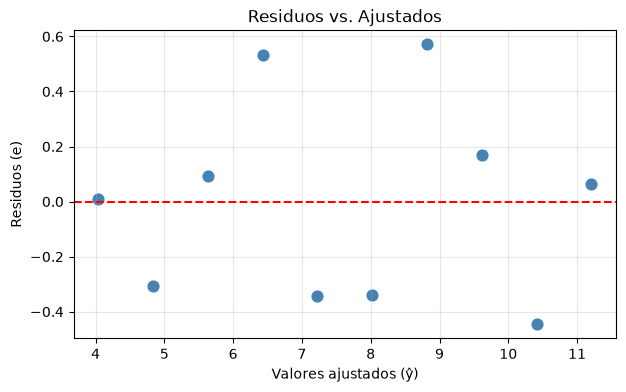

In [14]:
#residuos y  ajustados
plt.figure(figsize=(7, 4))
plt.scatter(y_hat, e, color='steelblue', s=60)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valores ajustados (ŷ)')
plt.ylabel('Residuos (e)')
plt.title('Residuos vs. Ajustados')
plt.grid(alpha=0.3)
plt.show()

En el gráficos se ven los puntos dispersos alrededor del 0, sin forma de embudo, ni de curva, esto indica que se cumple linealidad, y varianza constante, llamado Homocedasticidad.

    X  residuo    h_ii  Cook_D
0   1   0.0088  0.3455  0.0002
1   2  -0.3052  0.2485  0.1395
2   3   0.0912  0.1758  0.0073
3   4   0.5323  0.1273  0.1612
4   5  -0.3428  0.1030  0.0512
5   6  -0.3394  0.1030  0.0502
6   7   0.5708  0.1273  0.1853
7   8   0.1683  0.1758  0.0249
8   9  -0.4467  0.2485  0.2988
9  10   0.0628  0.3455  0.0108

Umbral 4/n = 0.4
Observaciones influyentes: []


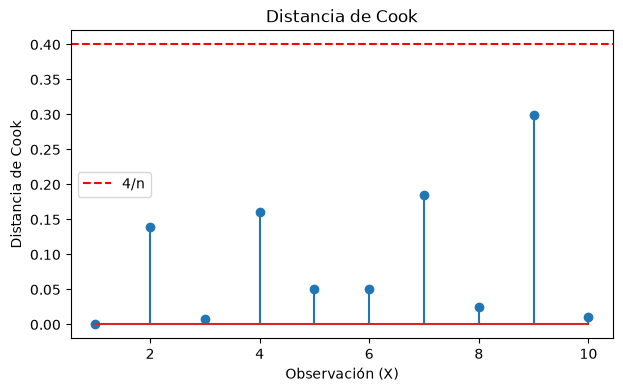

In [15]:
#distancia de cook
H = X_design @ XtX_inv @ X_design.T
h = np.diag(H)
p = 2

D = (e**2 / (p * MSE)) * (h / (1 - h)**2)

cook = pd.DataFrame({'X': X, 'residuo': e, 'h_ii': h, 'Cook_D': D})
print(cook.round(4))

umbral = 4 / n
print("\nUmbral 4/n =", umbral)
print("Observaciones influyentes:", cook[cook['Cook_D'] > umbral]['X'].tolist())

plt.figure(figsize=(7, 4))
plt.stem(X, D)
plt.axhline(umbral, color='red', linestyle='--', label='4/n')
plt.xlabel('Observación (X)')
plt.ylabel('Distancia de Cook')
plt.title('Distancia de Cook')
plt.legend()
plt.show()

Interpretación
El punto con mayor distancia de cook es X=9 (D=0.2988).No es el de residuo más grande (ese es X = 7, con 0.5708), pero combina un residuo considerable (−0.4467) con un leverage mayor (h = 0.2485). En cambio, X = 1 y X = 10 tienen el leverage más alto (0.3455), pero sus residuos son casi cero, por eso su Cook es mínimo. Esto confirma que la influencia depende de las dos cosas a la vez: qué tan lejos está el punto de la recta y qué tan extremo es su valor de X.

## Parte II Regresión Múltiple y multicolinealidad (25 puntos)

In [19]:
from sklearn.datasets import load_wine

pd.set_option('display.width', 200)   # para que no corte las tablas con "..."

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)

predictores = ['total_phenols', 'od280/od315_of_diluted_wines', 'proline']
y = X['flavanoids'].values
X_pred = X[predictores]

n = len(y)    # 178
p = 3         # número de predictores
print("n =", n)
X[predictores + ['flavanoids']].head()

n = 178


,total_phenols,od280/od315_of_diluted_wines,proline,flavanoids
0,2.80,3.92,1065.0,3.06
1,2.65,3.40,1050.0,2.76
2,2.80,3.17,1185.0,3.24
3,3.85,3.45,1480.0,3.49
4,2.80,2.93,735.0,2.69


**Predictores:** total_phenols, ods280,/ods315_of_diluted_wines, proline

**Respuestas:** flavanoides (variable continua, concentración de flavonoides)

#### 1. Exploración

                              total_phenols  od280/od315_of_diluted_wines  proline  flavanoids
total_phenols                        1.0000                        0.6999   0.4981      0.8646
od280/od315_of_diluted_wines         0.6999                        1.0000   0.3128      0.7872
proline                              0.4981                        0.3128   1.0000      0.4942
flavanoids                           0.8646                        0.7872   0.4942      1.0000


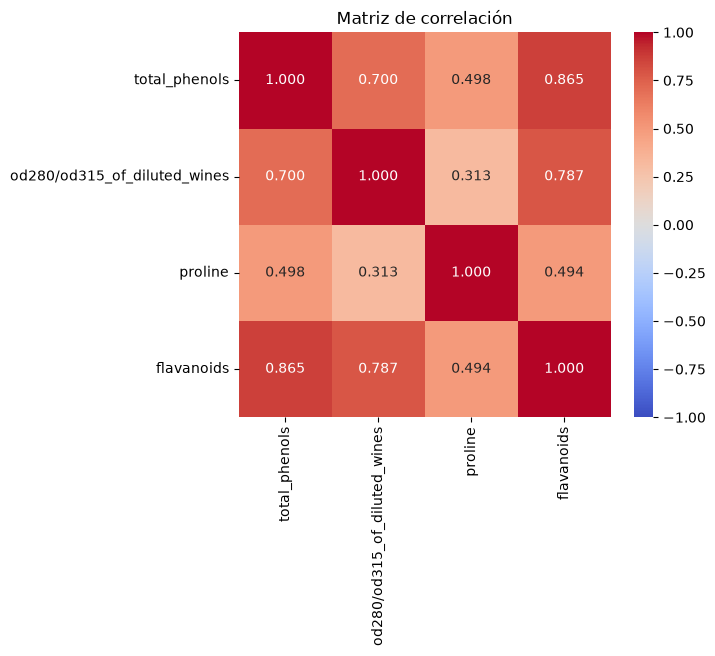

In [24]:
corr = X[predictores + ['flavanoids']].corr()
print(corr.round(4))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()

In [22]:
nombres_cortos = {
    'total_phenols': 'total_phenols',
    'od280/od315_of_diluted_wines': 'od280',
    'proline': 'proline',
    'flavanoids': 'flavanoids'
}

corr = X[predictores + ['flavanoids']].corr().rename(index=nombres_cortos, columns=nombres_cortos)
print(corr.round(4))

               total_phenols   od280  proline  flavanoids
total_phenols         1.0000  0.6999   0.4981      0.8646
od280                 0.6999  1.0000   0.3128      0.7872
proline               0.4981  0.3128   1.0000      0.4942
flavanoids            0.8646  0.7872   0.4942      1.0000


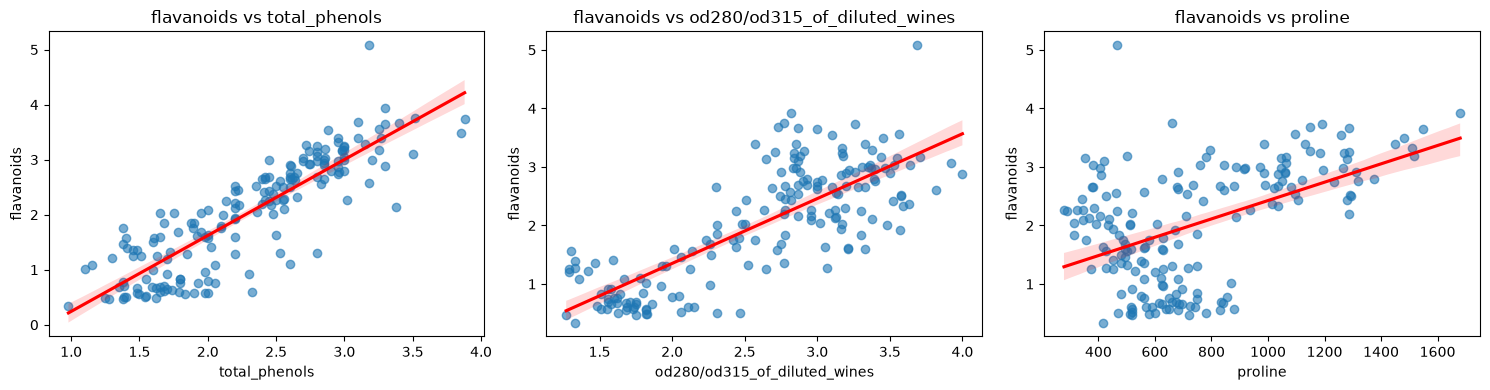

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(predictores):
    sns.regplot(x=X[col], y=X['flavanoids'], ax=axes[i],
                scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
    axes[i].set_title(f'flavanoids vs {col}')
plt.tight_layout()
plt.show()

Interpretación
El par de predictores más correlacionado es total_phenols y od280 (r = 0.70). Entre los predictores, total_phenols es el que tiene la relación más fuerte con flavanoids (r = 0.86) y proline la más débil (r = 0.49).

#### 2. Solución matricial 

In [25]:
X_design = np.column_stack([np.ones(n), X_pred.values])   # n x 4
print("Dimensión X_design:", X_design.shape)

XtX_inv = np.linalg.inv(X_design.T @ X_design)
beta = XtX_inv @ X_design.T @ y

y_hat = X_design @ beta
e = y - y_hat

gl_err = n - p - 1
MSE = np.sum(e**2) / gl_err

SE = np.sqrt(MSE * np.diag(XtX_inv))
t_vals = beta / SE
p_vals = 2 * stats.t.sf(np.abs(t_vals), gl_err)

coefs = pd.DataFrame({'Coef': beta, 'SE': SE, 't': t_vals},
                     index=['Intercepto'] + predictores).round(4)
coefs['p-valor'] = [f"{v:.2e}" for v in p_vals]
print(coefs)

Dimensión X_design: (178, 4)
                                Coef      SE        t   p-valor
Intercepto                   -1.5974  0.1339 -11.9324  2.29e-24
total_phenols                 0.8921  0.0788  11.3192  1.31e-22
od280/od315_of_diluted_wines  0.5122  0.0634   8.0755  1.07e-13
proline                       0.0003  0.0001   2.7440  6.71e-03


Modelo: flavanoids = −1.5974 + 0.8921·phenols + 0.5122·od280 + 0.000323·proline


#### 3. Tabla ANOVA múltiple

In [26]:
y_bar = y.mean()
SST = np.sum((y - y_bar)**2)
SSR = np.sum((y_hat - y_bar)**2)
SSE = np.sum(e**2)

gl_reg = p
MSR = SSR / gl_reg
F = MSR / MSE
p_F = stats.f.sf(F, gl_reg, gl_err)

R2 = SSR / SST
R2_adj = 1 - (1 - R2) * (n - 1) / (n - p - 1)

anova = pd.DataFrame({
    'Fuente': ['Regresión', 'Error', 'Total'],
    'gl': [gl_reg, gl_err, n - 1],
    'SC': [round(SSR, 4), round(SSE, 4), round(SST, 4)],
    'CM': [round(MSR, 4), round(MSE, 4), ''],
    'F': [round(F, 4), '', ''],
    'p-valor': [f"{p_F:.2e}", '', '']
})
print(anova.to_string(index=False))
print("\n¿SST = SSR + SSE?", np.isclose(SST, SSR + SSE))
print("R²     =", round(R2, 4))
print("R² adj =", round(R2_adj, 4))

   Fuente  gl       SC       CM         F  p-valor
Regresión   3 144.8478  48.2826  264.6172 1.39e-64
    Error 174  31.7484   0.1825                   
    Total 177 176.5962                            

¿SST = SSR + SSE? True
R²     = 0.8202
R² adj = 0.8171


Interpretación
Como p-valor <0.05 , se rechaza H0, loq ue nos dice que al emenos un predictor explica flavonoids.
La R cuadrada nos dice que el modelo explica  cerca del 82% de las variables

#### 4. Multicolinealidad (VIF)

In [27]:
def r2_regresion(y_aux, X_aux):
    """Ajusta y_aux ~ X_aux por MCO matricial y regresa la R²."""
    A = np.column_stack([np.ones(len(y_aux)), X_aux])
    b = np.linalg.inv(A.T @ A) @ A.T @ y_aux
    residuos = y_aux - A @ b
    return 1 - np.sum(residuos**2) / np.sum((y_aux - y_aux.mean())**2)

vif_lista = []
for col in predictores:
    otros = [c for c in predictores if c != col]
    R2_j = r2_regresion(X_pred[col].values, X_pred[otros].values)
    vif_lista.append({'Variable': col, 'R²_j': R2_j, 'VIF': 1 / (1 - R2_j)})

vif = pd.DataFrame(vif_lista).round(4)
print(vif.to_string(index=False))

                    Variable   R²_j    VIF
               total_phenols 0.5763 2.3603
od280/od315_of_diluted_wines 0.4916 1.9671
                     proline 0.2506 1.3345


Interpretación:
En este caso, ninguna variables tinene problema grave, tdoos los VIF están muy por debajo del 10, incluso de 5, que es critero mpas estricto. El más alto es total_phenois (2.36), lo cual tienen sentido porque es el que mas de correlaciona con los otros dos. 

#### 5. Leverage y cook

In [28]:
H = X_design @ XtX_inv @ X_design.T
h = np.diag(H)

k = p + 1                      # parámetros estimados (4)
umbral_h = 2 * k / n
D = (e**2 / (k * MSE)) * (h / (1 - h)**2)

diag = pd.DataFrame({'h_ii': h, 'residuo': e, 'Cook_D': D})

print("Umbral leverage 2p/n =", round(umbral_h, 4))
alto_lev = diag[diag['h_ii'] > umbral_h]
print("Observaciones con alto leverage:", len(alto_lev))
print(alto_lev.round(4))

print("\nObservaciones con Cook > 1:", diag[diag['Cook_D'] > 1].index.tolist())
print("\nTop 5 Cook:")
print(diag.sort_values('Cook_D', ascending=False).head().round(4))

Umbral leverage 2p/n = 0.0449
Observaciones con alto leverage: 8
       h_ii  residuo  Cook_D
3    0.0523  -0.5927  0.0280
14   0.0457   0.2568  0.0045
18   0.0612   0.5960  0.0338
52   0.0501  -0.1785  0.0024
63   0.0695  -0.0309  0.0001
98   0.0552   0.5750  0.0280
105  0.0459   0.1465  0.0015
152  0.0463   0.0961  0.0006

Observaciones con Cook > 1: []

Top 5 Cook:
       h_ii  residuo  Cook_D
121  0.0384   1.8001  0.1844
74   0.0267  -1.1676  0.0527
150  0.0252   1.0909  0.0433
158  0.0383  -0.8078  0.0370
18   0.0612   0.5960  0.0338


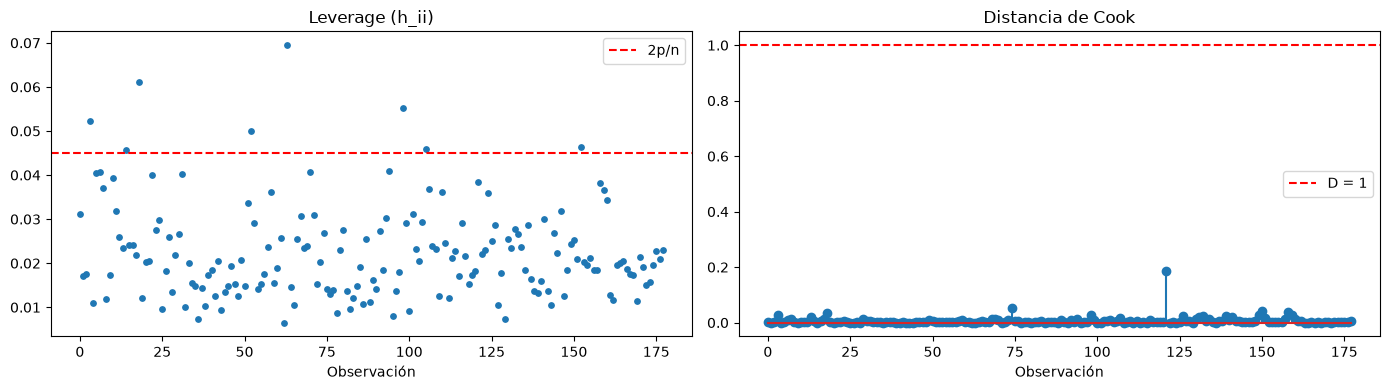

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].scatter(range(n), h, s=15)
axes[0].axhline(umbral_h, color='red', linestyle='--', label='2p/n')
axes[0].set_title('Leverage (h_ii)')
axes[0].set_xlabel('Observación')
axes[0].legend()

axes[1].stem(range(n), D)
axes[1].axhline(1, color='red', linestyle='--', label='D = 1')
axes[1].set_title('Distancia de Cook')
axes[1].set_xlabel('Observación')
axes[1].legend()

plt.tight_layout()
plt.show()

Interpretación: hay algunos vinos con valores de X poco comunes (alto leverage), pero ninguno mueve la recta de forma importante. Alto leverage no significa automáticamente influyente: un punto también necesita un residuo grande para serlo. Ningúna de las obervaciones tineen Cook > 1. Ocho observaciones superan el umbral de leverage (h > 0.0449), es decir, tienen combinaciones poco comunes de los predictores. Sin embargo, sus residuos son pequeños y su distancia de Cook es baja (máx. 0.034), así que no influyen en el modelo. Por lo que no hay obervaciones influyentes que obliguen a eliminar datos.

#### 6. Comparación de modelos

In [30]:
def metricas_modelo(X_mod, nombre):
    A = np.column_stack([np.ones(n), X_mod])
    b = np.linalg.inv(A.T @ A) @ A.T @ y
    sse = np.sum((y - A @ b)**2)
    k = A.shape[1]                      # parámetros incluyendo intercepto

    r2 = 1 - sse / SST
    r2_adj = 1 - (1 - r2) * (n - 1) / (n - k)
    logL = -n/2 * (np.log(2*np.pi) + np.log(sse/n) + 1)
    aic = -2*logL + 2*k
    bic = -2*logL + k*np.log(n)
    return {'Modelo': nombre, 'k': k, 'R²': r2, 'R² adj': r2_adj,
            'log L': logL, 'AIC': aic, 'BIC': bic}

col_max_vif = vif.loc[vif['VIF'].idxmax(), 'Variable']
reducidos = [c for c in predictores if c != col_max_vif]
print("Variable eliminada:", col_max_vif)

comparacion = pd.DataFrame([
    metricas_modelo(X_pred.values, 'Completo (3 var)'),
    metricas_modelo(X_pred[reducidos].values, f'Reducido (sin {col_max_vif})')
]).round(4)
print(comparacion.to_string(index=False))

Variable eliminada: total_phenols
                      Modelo  k     R²  R² adj     log L      AIC      BIC
            Completo (3 var)  4 0.8202  0.8171  -99.1403 206.2806 219.0077
Reducido (sin total_phenols)  3 0.6878  0.6843 -148.2488 302.4975 312.0429


In [31]:
A_red = np.column_stack([np.ones(n), X_pred[reducidos].values])
beta_red = np.linalg.inv(A_red.T @ A_red) @ A_red.T @ y

signos = pd.DataFrame({
    'Completo': beta[[0] + [predictores.index(c) + 1 for c in reducidos]],
    'Reducido': beta_red
}, index=['Intercepto'] + reducidos)
print(signos.round(6))

                              Completo  Reducido
Intercepto                   -1.597353 -1.198428
od280/od315_of_diluted_wines  0.512193  0.986524
proline                       0.000323  0.000872


Inpertretación
El modelo completo es mejor, tiene una R cuadrada ajustada más alta y tanto el AIC, como el BIC más bajos. en este caso quitar total_phenols fue mala idea porque, aunque es el mayor VIF, también es el mejor predictor de flavnoids. Como su VIF era bajo, no había razón para dejarlo afuera.


#### Preguntas

**¿Qué aporta el VIF que R² no captura?**

La R² del modelo solo dice qué tan bien los predictores, en conjunto, explican la respuesta. No dice nada de cómo se relacionan los predictores entre sí. Un modelo puede tener R² alta y aun así coeficientes muy inestables, porque dos variables cargan casi la misma información. El VIF mide justo eso: cuánto se infla la varianza de cada coeficiente por estar correlacionado con los demás predictores. R² evalúa el ajuste global y el VIF evalúa la confiabilidad de cada coeficiente por separado.

**¿Qué implica que un coeficiente cambie de signo al eliminar otra variable?**
Es una señal de multicolinealidad. El coeficiente estaba repartiendo su efecto con la variable eliminada, así que su valor dependía de qué otras variables hubiera en el modelo y no reflejaba un efecto propio estable. En la práctica, eso hace que la interpretación sea poco confiable (“si X sube, Y sube” deja de ser válido). En nuestro caso ningún signo cambió y solo aumentó la magnitud, lo cual confirma lo que dijeron los VIF: hay algo de correlación entre predictores, pero no es grave.

## Parte 3 -Clasificación con regresión logística (EXTRA 5 puntos)

In [36]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from sklearn.dummy import DummyClassifier

pd.set_option('display.width', 200)

data = load_iris()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

#### 1. Filtrar 

In [37]:
# Quedarnos solo con versicolor (1) y virginica (2)
filtro = y.isin([1, 2])
X = X[filtro].reset_index(drop=True)
y = y[filtro].reset_index(drop=True)

# Recodificar: versicolor -> 0, virginica -> 1
y = y - 1
print("n =", len(y))
print(y.value_counts())

# División 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)
print("Proporción clase 1 en train:", y_train.mean(), "| en test:", y_test.mean())

# Estandarizar (se ajusta SOLO con train)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

n = 100
0    50
1    50
Name: count, dtype: int64

Train: (80, 4) | Test: (20, 4)
Proporción clase 1 en train: 0.5 | en test: 0.5


#### 2. Regresión Logística

In [40]:
# C muy grande = sin penalización 
modelo = LogisticRegression(C=1e10, max_iter=1000)
modelo.fit(X_train_s, y_train)

beta = np.r_[modelo.intercept_, modelo.coef_[0]]

# Errores estándar
X_design = np.column_stack([np.ones(len(X_train_s)), X_train_s])
p_hat = modelo.predict_proba(X_train_s)[:, 1]
W = np.diag(p_hat * (1 - p_hat))
cov_beta = np.linalg.inv(X_design.T @ W @ X_design)
SE = np.sqrt(np.diag(cov_beta))

# z, p-valor, OR e IC
z = beta / SE
p_vals = 2 * stats.norm.sf(np.abs(z))
OR = np.exp(beta)
OR_inf = np.exp(beta - 1.96 * SE)
OR_sup = np.exp(beta + 1.96 * SE)

tabla = pd.DataFrame({
    'β': beta, 'SE': SE, 'z': z, 'p-valor': p_vals,
    'OR': OR, 'IC OR 2.5%': OR_inf, 'IC OR 97.5%': OR_sup
}, index=['Intercepto'] + list(X.columns))
print(tabla.round(4))

                        β      SE       z  p-valor        OR  IC OR 2.5%  IC OR 97.5%
Intercepto         0.4583  0.9513  0.4818   0.6300    1.5814      0.2451      10.2042
sepal length (cm) -1.0749  2.2288 -0.4823   0.6296    0.3413      0.0043      26.9404
sepal width (cm)  -0.8660  2.0993 -0.4125   0.6800    0.4206      0.0069      25.7549
petal length (cm)  5.3673  3.9974  1.3427   0.1794  214.2785      0.0848  541591.5473
petal width (cm)   6.5631  3.2618  2.0121   0.0442  708.4663      1.1854  423438.5782


#### 3. Interpretación

In [41]:
top2 = tabla.drop('Intercepto')['β'].abs().sort_values(ascending=False).head(2)
print(top2)

petal width (cm)     6.563102
petal length (cm)    5.367276
Name: β, dtype: float64


Como los predictores están estandarizados, el OR se interpreta por cada aumento de 1 desviación estándar:

petal width (OR = 708.5): si el ancho del pétalo aumenta 1 desviación estándar, manteniendo lo demás constante, los odds de que la flor sea virginica se multiplican por unas 708. Es el único predictor significativo (p = 0.044) y su IC no incluye el 1.
petal length (OR = 214.3): si el largo del pétalo aumenta 1 desviación estándar, los odds de ser virginica se multiplican por unas 214. Sin embargo, no es significativo (p = 0.18) y su IC incluye el 1. Lo más probable es que esté muy correlacionado con petal width y compitan por el mismo efecto, lo que infla su SE.

Esto nos dice qeue pétalos más grandes significan una mayor probabilidad virginica.

#### 4. Evaluación

Matriz de confusión:
 [[ 9  1]
 [ 0 10]]

Accuracy:      0.9500
Sensibilidad:  1.0000
Especificidad: 0.9000
AUC:           0.9900


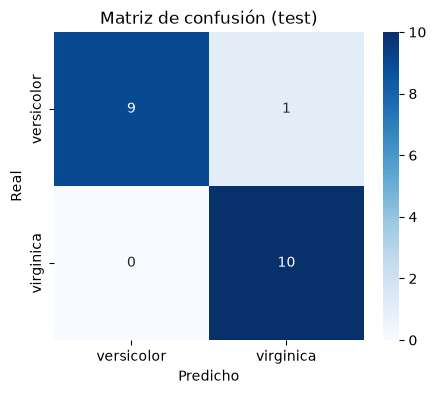

In [42]:
y_pred = modelo.predict(X_test_s)               # umbral 0.5 por defecto
y_prob = modelo.predict_proba(X_test_s)[:, 1]

cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)
sensibilidad = TP / (TP + FN)
especificidad = TN / (TN + FP)
auc = roc_auc_score(y_test, y_prob)

print("Matriz de confusión:\n", cm)
print(f"\nAccuracy:      {accuracy:.4f}")
print(f"Sensibilidad:  {sensibilidad:.4f}")
print(f"Especificidad: {especificidad:.4f}")
print(f"AUC:           {auc:.4f}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['versicolor', 'virginica'],
            yticklabels=['versicolor', 'virginica'])
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title('Matriz de confusión (test)')
plt.show()

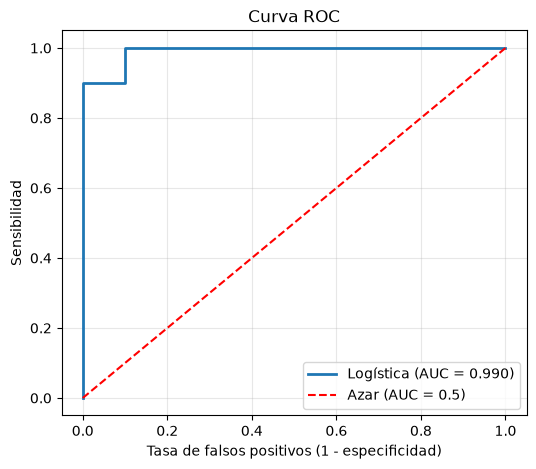

In [43]:
#curva roc 
fpr, tpr, umbrales = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logística (AUC = {auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'r--', label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (1 - especificidad)')
plt.ylabel('Sensibilidad')
plt.title('Curva ROC')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Interpretación:
El modelo detecta todas las virginica (sensibilidad del 100%) y solo confunde una versicolor como virginica. El AUC de 0.99 indica que separa casi perfectamente las dos clases.

#### 5. Baseline

In [44]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train_s, y_train)

acc_base = accuracy_score(y_test, baseline.predict(X_test_s))
auc_base = roc_auc_score(y_test, baseline.predict_proba(X_test_s)[:, 1])

comparacion = pd.DataFrame({
    'Modelo': ['Baseline (clase mayoritaria)', 'Logística'],
    'Accuracy': [acc_base, accuracy],
    'AUC': [auc_base, auc]
})
comparacion['Mejora'] = ['', f"+{accuracy - acc_base:.2f} acc / +{auc - auc_base:.2f} AUC"]
print(comparacion.to_string(index=False))

                      Modelo  Accuracy  AUC                Mejora
Baseline (clase mayoritaria)      0.50 0.50                      
                   Logística      0.95 0.99 +0.45 acc / +0.49 AUC


El modelo logístico mejora 45 puntos porcentuales en accuracy (de 0.50 a 0.95) y 0.49 en AUC (de 0.50 a 0.99). Como las clases están balanceadas 50/50, el baseline no tiene una clase mayoritaria real: en caso de empate, predice siempre versicolor (clase 0). Por eso acierta el 50% y su AUC es 0.5, lo que significa que no distingue entre clases, igual que adivinar al azar.

<!-- El modelo logístico mejora 45 puntos porcentuales en accuracy y 0.49 en AUC. El baseline predice siempre la misma clase, así que acierta el 50% (porque las clases están balanceadas) y su AUC es 0.5, es decir, no distingue nada. Es como tirar una moneda. -->

#### Preguntas

**¿Qué variables son significativas?**

Solo petal width (p = 0.044). Las otras tres no lo son con α = 0.05. Petal length tiene un coeficiente grande, pero un SE también grande, probablemente por su alta correlación con petal width: las dos aportan casi la misma información y el modelo no puede separar el efecto de cada una.

**¿El modelo clasifica bien?**

Sí. En los datos de prueba tiene accuracy de 0.95, sensibilidad de 1.00, especificidad de 0.90 y AUC de 0.99, muy por encima del baseline. Hay que tomarlo con cautela porque el conjunto de prueba es pequeño (20 flores): un solo error cambia el accuracy 5 puntos.Hay ciertas limitaciones de usar Hosmer-Lemeshow como único criterio único: La prueba de Hosmer-Lemeshow solo evalúa la calibración del modelo, es decir, si las probabilidades predichas se parecen a las proporciones observadas. No dice nada sobre la capacidad del modelo para discriminar entre clases. Además, su resultado depende de cuántos grupos se formen (normalmente 10), así que con otra agrupación la conclusión puede cambiar. También es sensible al tamaño de muestra: con pocos datos, como en este caso, tiene poco poder y casi nunca rechaza aunque el modelo sea malo; con muestras muy grandes, en cambio, rechaza por diferencias mínimas sin importancia práctica. Por último, no rechazar H₀ no demuestra que el modelo sea bueno, solo que no hay evidencia de mala calibración. Por eso debe complementarse con otras métricas, como el AUC y la matriz de confusión.

**¿Por qué el AUC es más informativo que el accuracy con desbalance?**

El accuracy se infla con la clase mayoritaria. El AUC no depende de un umbral ni de la proporción de clases, porque mide qué tan bien el modelo ordena a los positivos por encima de los negativos.

Aquí el balance es 50/50, así que el accuracy sí es confiable (el baseline queda en 0.50). Pero si usáramos setosa vs. el resto (50 contra 100, o sea 33/67), un modelo que diga siempre “no es setosa” tendría 67% de accuracy sin aprender nada, y aun así su AUC sería 0.5. Además, setosa se separa perfectamente de las otras especies, así que la logística tendría problemas de convergencia: los coeficientes tenderían a infinito por la separación perfecta.